# Hotel Bookings: Preprocessing and Exploratory Data Analysis

Preserve `raw_bookings` and analyze `bookings_copy`. Remove leakage columns, keep the first
occurrence of duplicate records, and remove rows where adults, children and babies are all zero.
All subsequent statistics and plots use the cleaned copy. IQR outliers are flagged, not removed.

Use the existing loader in `src/data_loader.py` and reusable analysis functions in `src/eda.py`.
Only ten selected features have observed-value listings. Plots cover IQR outliers, seasonal and
yearly prices, and monthly/yearly booked guest counts for both hotels.

No result folders, chart files or analysis tables are exported. The final optional cell saves
only `bookings_copy` to `data/bookings_preprocessed_copy.csv` when you run it.
Run the notebook from top to bottom; leave the export cell unexecuted unless you want the CSV.

[Go to the correlation matrix](#correlation-matrix).

## 1. Project Location and Imports

In [2]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML
from IPython.display import display


def find_project_root(start: Path) -> Path:
    """Locate this project using its existing loader, independently of notebook cwd."""
    candidates = [start, *start.parents, start / "hotel-cancellation"]
    for candidate in candidates:
        if (candidate / "src" / "data_loader.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the hotel-cancellation project. "
        "Run the notebook from the project root or the notebooks/ directory."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_hotel_bookings
from src.eda import (
    LEAKAGE_COLUMNS, NUMERIC_COLUMNS, OUTLIER_COLUMNS, VALUE_COUNT_COLUMNS,
    feature_value_counts, duplicate_summary, iqr_outliers,
    plot_iqr_checks, seasonal_room_prices, plot_seasonal_prices,
    zero_guest_mask, yearly_room_prices, guest_counts, plot_hotel_trends,
)


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
print(f"Project directory: {PROJECT_ROOT}")

Project directory: C:\Users\lenovo\Documents\CODING\cmpe481_term_project\hotel-cancellation


## 2. Load Data Using the Existing Loader

In [3]:
raw_bookings = load_hotel_bookings()
raw_fingerprint = pd.util.hash_pandas_object(raw_bookings, index=True).copy()

print(f"Row count: {raw_bookings.shape[0]:,}")
print(f"Column count: {raw_bookings.shape[1]}")
display(raw_bookings.head())

Row count: 119,390
Column count: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NULL,NULL,0,Transient,0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NULL,NULL,0,Transient,0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NULL,NULL,0,Transient,75,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,NULL,0,Transient,75,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,NULL,0,Transient,98,0,1,Check-Out,2015-07-03


## 3. `info()` — Raw Data Structure

The loader reads every column as `string` and uses `keep_default_na=False`.
Consequently, `Non-Null Count` treats literal strings such as `NULL` and `NA` as populated values.
This output alone does not establish the semantic types of the columns.

In [4]:
raw_bookings.info(show_counts=True, memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype 
---  ------                          --------------   ----- 
 0   hotel                           119390 non-null  string
 1   is_canceled                     119390 non-null  string
 2   lead_time                       119390 non-null  string
 3   arrival_date_year               119390 non-null  string
 4   arrival_date_month              119390 non-null  string
 5   arrival_date_week_number        119390 non-null  string
 6   arrival_date_day_of_month       119390 non-null  string
 7   stays_in_weekend_nights         119390 non-null  string
 8   stays_in_week_nights            119390 non-null  string
 9   adults                          119390 non-null  string
 10  children                        119390 non-null  string
 11  babies                          119390 non-null  string
 12  meal                          

## 4. `describe()` — Raw Value Summary

Because the raw columns are strings, this output shows `count`, `unique`, `top`, and `freq`.
Numeric means and quantiles are calculated below using a separate analysis copy.

In [5]:
display(raw_bookings.describe(include="all").T)

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
is_canceled,119390,2,0,75166
lead_time,119390,479,0,6345
arrival_date_year,119390,3,2016,56707
arrival_date_month,119390,12,August,13877
arrival_date_week_number,119390,53,33,3580
arrival_date_day_of_month,119390,31,17,4406
stays_in_weekend_nights,119390,17,0,51998
stays_in_week_nights,119390,35,2,33684
adults,119390,14,2,89680


## 5. Null and Missing-Value Checks

First inspect pandas null counts, then audit textual missing-value markers in the file.
`NULL`, `NA`, `N/A`, `NaN`, `nan`, `null`, empty strings, and whitespace-only cells are treated as missing candidates.
Update the single configuration below if the dataset's missing-value policy changes.
`None` and `Unknown` are not automatically treated as missing.

`pandas_null_count`, `blank_count`, and `missing_token_count` are mutually exclusive counts.
Percentages use all rows as the denominator. Raw values remain unchanged.

In [6]:
# Literal tokens in this CSV are audited separately from actual pandas nulls.
MISSING_TOKENS = frozenset({"NULL", "null", "NA", "N/A", "NaN", "nan"})


def missing_value_summary(
    frame: pd.DataFrame,
    missing_tokens: frozenset[str],
) -> pd.DataFrame:
    """Report actual nulls, blanks and configured textual markers without mutation."""
    rows = []
    for column in frame.columns:
        values = frame[column].astype("string")
        stripped = values.str.strip()
        nulls = values.isna()
        blanks = stripped.eq("").fillna(False) & ~nulls
        tokens = stripped.isin(missing_tokens) & ~nulls & ~blanks
        total = int((nulls | blanks | tokens).sum())
        rows.append({
            "column": column,
            "pandas_null_count": int(nulls.sum()),
            "blank_count": int(blanks.sum()),
            "missing_token_count": int(tokens.sum()),
            "total_missing_count": total,
            "missing_percent": 100 * total / len(frame) if len(frame) else 0.0,
        })
    return pd.DataFrame(rows).set_index("column").sort_values(
        "total_missing_count", ascending=False
    )


print("Direct pandas isna() check:")
display(raw_bookings.isna().sum().rename("pandas_null_count").to_frame())

missing_summary = missing_value_summary(raw_bookings, MISSING_TOKENS)
print("Missing-value check including textual markers:")
display(missing_summary)
print(f"Total candidate missing cells: {missing_summary['total_missing_count'].sum():,}")

Direct pandas isna() check:


,pandas_null_count
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


Missing-value check including textual markers:


,pandas_null_count,blank_count,missing_token_count,total_missing_count,missing_percent
column,,,,,
company,0,0,112593,112593,94.306893
agent,0,0,16340,16340,13.686238
country,0,0,488,488,0.408744
children,0,0,4,4,0.003350
arrival_date_month,0,0,0,0,0.000000
arrival_date_week_number,0,0,0,0,0.000000
hotel,0,0,0,0,0.000000
is_canceled,0,0,0,0,0.000000
stays_in_weekend_nights,0,0,0,0,0.000000


Total candidate missing cells: 129,425


## 6. Create `bookings_copy` and Remove Leakage Columns

Normalize missing markers and convert explicitly configured numeric fields on a separate copy.
Unexpected numeric text raises an error. `agent` and `company` remain string codes.
Drop `reservation_status` and `reservation_status_date` from the copy only.
Other fields may also be unavailable at prediction time and need a later domain review.
Binary labels and calendar codes are not continuous measurements.

In [7]:
def build_bookings_copy(
    frame: pd.DataFrame,
    numeric_columns: tuple[str, ...],
    missing_tokens: frozenset[str],
) -> pd.DataFrame:
    """Return an analysis copy; explicit numeric conversions fail on unknown values."""
    absent = sorted(set(numeric_columns) - set(frame.columns))
    if absent:
        raise ValueError(f"Expected numeric columns not found: {absent}")
    view = frame.copy(deep=True)
    for column in view.columns:
        stripped = view[column].astype("string").str.strip()
        missing = stripped.isin(missing_tokens) | stripped.eq("").fillna(False)
        view[column] = view[column].mask(missing, pd.NA)
    for column in numeric_columns:
        view[column] = pd.to_numeric(view[column], errors="raise")
    return view


bookings_copy = build_bookings_copy(
    raw_bookings, NUMERIC_COLUMNS, MISSING_TOKENS
).drop(columns=list(LEAKAGE_COLUMNS))
bookings_copy.info(show_counts=True)

# Each candidate missing cell must appear in the analysis copy as a pandas null.
assert bookings_copy.isna().sum().eq(missing_summary.loc[bookings_copy.columns, "total_missing_count"]).all()
assert len(raw_bookings) == len(bookings_copy)
assert bookings_copy.shape[1] == raw_bookings.shape[1] - len(LEAKAGE_COLUMNS)
assert not set(LEAKAGE_COLUMNS).intersection(bookings_copy.columns)
print(f"Analysis copy: {bookings_copy.shape[0]:,} rows, {bookings_copy.shape[1]} columns")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 30 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  string 
 1   is_canceled                     119390 non-null  Int64  
 2   lead_time                       119390 non-null  Int64  
 3   arrival_date_year               119390 non-null  Int64  
 4   arrival_date_month              119390 non-null  string 
 5   arrival_date_week_number        119390 non-null  Int64  
 6   arrival_date_day_of_month       119390 non-null  Int64  
 7   stays_in_weekend_nights         119390 non-null  Int64  
 8   stays_in_week_nights            119390 non-null  Int64  
 9   adults                          119390 non-null  Int64  
 10  children                        119386 non-null  Int64  
 11  babies                          119390 non-null  Int64  
 12  meal            

### 6.1. Remove Duplicate and All-Zero Guest Rows

After normalization and leakage-column removal, keep only the first occurrence of each identical
row. Then remove rows where adults, babies and children are all explicitly zero.
A missing count is not interpreted as zero. Retain original row indices and report removals
sequentially to avoid double counting. All following copy-level statistics use the cleaned copy.

In [8]:
duplicates_before_cleaning = duplicate_summary(bookings_copy)
duplicate_rows_removed = int(bookings_copy.duplicated(keep="first").sum())
bookings_copy = bookings_copy.drop_duplicates(keep="first").copy()
zero_guests = zero_guest_mask(bookings_copy)
zero_guest_rows_removed = int(zero_guests.sum())
bookings_copy = bookings_copy.loc[~zero_guests].copy()
print(f"Additional duplicate rows removed: {duplicate_rows_removed:,}")
print(f"All-zero guest rows removed after deduplication: {zero_guest_rows_removed:,}")
print(f"Remaining rows: {len(bookings_copy):,}")

Additional duplicate rows removed: 32,252
All-zero guest rows removed after deduplication: 166
Remaining rows: 86,972


## 7. Numeric `describe()`

`count` is the number of nonmissing observations. `std` is the sample standard deviation (ddof=1).
Inspect the 25th, 50th (median), and 75th percentiles alongside the minimum and maximum.
An extreme value alone is not sufficient justification for removing a record.

In [9]:
numeric_summary = bookings_copy.loc[:, list(NUMERIC_COLUMNS)].describe().T
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
is_canceled,86972.0,0.273088,0.445548,0.0,0.0,0.0,1.0,1.0
lead_time,86972.0,79.799683,85.950555,0.0,11.0,49.0,125.0,737.0
arrival_date_year,86972.0,2016.210585,0.685966,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,86972.0,26.833107,13.669262,1.0,16.0,27.0,37.0,53.0
arrival_date_day_of_month,86972.0,15.814699,8.835557,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,86972.0,1.004588,1.027002,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,86972.0,2.623879,2.037817,0.0,1.0,2.0,4.0,50.0
adults,86972.0,1.879421,0.622007,0.0,2.0,2.0,2.0,55.0
children,86968.0,0.13912,0.456608,0.0,0.0,0.0,0.0,10.0
babies,86972.0,0.010877,0.113871,0.0,0.0,0.0,0.0,10.0


## 8. Categorical and Text `describe()`

`top` is the most frequent value and `freq` is its count. Missing values are excluded from `count`.
Code fields such as `agent` and `company` remain strings.

In [10]:
categorical_summary = bookings_copy.select_dtypes(
    include=["string", "object", "category", "bool"]
).describe().T
display(categorical_summary)

,count,unique,top,freq
hotel,86972,2,City Hotel,53099
arrival_date_month,86972,12,August,11222
meal,86972,5,BB,67714
country,86526,177,PRT,27194
market_segment,86972,8,Online TA,51437
distribution_channel,86972,5,TA/TO,68801
reserved_room_type,86972,9,A,56228
assigned_room_type,86972,11,A,46080
deposit_type,86972,3,No Deposit,85848
agent,74864,333,9,28647


## 9. Observed Values for Selected Features

List values, counts and percentages for exactly these features:
`hotel`, `is_canceled`, `arrival_date_year`, `meal`, `market_segment`, `distribution_channel`,
`reserved_room_type`, `assigned_room_type`, `deposit_type`, `customer_type`.

Counts use the cleaned `bookings_copy`. Missing entries are included when present.
Expand each feature below to inspect all of its observed values.

In [11]:
value_counts = feature_value_counts(bookings_copy, VALUE_COUNT_COLUMNS)
for feature in VALUE_COUNT_COLUMNS:
    counts = value_counts.loc[value_counts["feature"].eq(feature)].drop(columns="feature")
    content = counts.to_html(index=False, escape=True, float_format=lambda value: f"{value:.3f}")
    display(HTML(
        f"<details><summary><strong>{feature}</strong>: {len(counts):,} observed values</summary>"
        f"<div style='max-height:360px;overflow:auto'>{content}</div></details>"
    ))

value,is_missing,count,percent
City Hotel,False,53099,61.053
Resort Hotel,False,33873,38.947


value,is_missing,count,percent
0,False,63221,72.691
1,False,23751,27.309


value,is_missing,count,percent
2016,False,42191,48.511
2017,False,31548,36.274
2015,False,13233,15.215


value,is_missing,count,percent
BB,False,67714,77.857
SC,False,9376,10.780
HB,False,9044,10.399
Undefined,False,484,0.557
FB,False,354,0.407


value,is_missing,count,percent
Online TA,False,51437,59.142
Offline TA/TO,False,13810,15.879
Direct,False,11771,13.534
Groups,False,4844,5.570
Corporate,False,4190,4.818
Complementary,False,692,0.796
Aviation,False,226,0.260
Undefined,False,2,0.002


value,is_missing,count,percent
TA/TO,False,68801,79.107
Direct,False,12937,14.875
Corporate,False,5050,5.806
GDS,False,179,0.206
Undefined,False,5,0.006


value,is_missing,count,percent
A,False,56228,64.651
D,False,17342,19.940
E,False,6026,6.929
F,False,2818,3.240
G,False,2047,2.354
B,False,996,1.145
C,False,913,1.050
H,False,596,0.685
L,False,6,0.007


value,is_missing,count,percent
A,False,46080,52.983
D,False,22383,25.736
E,False,7180,8.256
F,False,3625,4.168
G,False,2492,2.865
C,False,2158,2.481
B,False,1809,2.080
H,False,706,0.812
I,False,353,0.406
K,False,185,0.213


value,is_missing,count,percent
No Deposit,False,85848,98.708
Non Refund,False,1017,1.169
Refundable,False,107,0.123


value,is_missing,count,percent
Transient,False,71732,82.477
Transient-Party,False,11565,13.297
Contract,False,3134,3.603
Group,False,541,0.622


## 10. Duplicate Check After Cleaning

Show duplicates in the raw data, the normalized copy before cleaning, and the final copy.
`additional_duplicate_rows` counts copies after the first; `rows_in_duplicate_groups`
includes all members. The final copy must contain no duplicates. First occurrences are retained.
Normalization and leakage-column removal can make previously different rows identical.

In [12]:
duplicates = pd.DataFrame({
    "raw_bookings": duplicate_summary(raw_bookings),
    "copy_before_cleaning": duplicates_before_cleaning,
    "bookings_copy": duplicate_summary(bookings_copy),
}).T
display(duplicates)

,rows,additional_duplicate_rows,rows_in_duplicate_groups,duplicate_groups,additional_duplicate_percent
raw_bookings,119390.0,31994.0,40165.0,8171.0,26.797889
copy_before_cleaning,119390.0,32252.0,40448.0,8196.0,27.013988
bookings_copy,86972.0,0.0,0.0,0.0,0.000000


## 11. IQR Bounds and Outlier Listings

- `IQR = Q3 - Q1`
- `upper_bound = Q3 + 1.5 * IQR`
- `lower_bound = Q1 - 1.5 * IQR`

Flag values strictly below the lower bound or strictly above the upper bound. Calculate bounds
after deduplication and zero-guest removal. Exclude missing observations, identifiers, binary
labels and calendar codes. Zero IQR can flag valid uncommon counts; no IQR outliers are removed.

The full listings remain in memory as `outlier_observations` and `outlier_bookings`.
Preview the first 20 observations per feature below. A booking may be flagged for several
features; observation counts and unique booking counts differ. Original row indices are retained.

In [12]:
IQR_MULTIPLIER = 1.5
iqr_summary, outlier_observations = iqr_outliers(
    bookings_copy, OUTLIER_COLUMNS, multiplier=IQR_MULTIPLIER
)
outlier_bookings = bookings_copy.loc[outlier_observations["source_row_index"].unique()].copy()
display(iqr_summary)
print(f"Flagged feature observations: {len(outlier_observations):,}")
print(f"Unique bookings flagged: {len(outlier_bookings):,}")
for feature in OUTLIER_COLUMNS:
    observations = outlier_observations.loc[outlier_observations["feature"].eq(feature)]
    print(f"{feature}: {len(observations):,} outliers. Preview: first 20 observations.")
    display(observations.head(20))

Flagged feature observations: 70,321
Unique bookings flagged: 47,148
lead_time: 2,369 outliers. Preview: first 20 observations.
stays_in_weekend_nights: 211 outliers. Preview: first 20 observations.
stays_in_week_nights: 1,507 outliers. Preview: first 20 observations.
adults: 22,659 outliers. Preview: first 20 observations.
children: 8,352 outliers. Preview: first 20 observations.
babies: 914 outliers. Preview: first 20 observations.
previous_cancellations: 1,657 outliers. Preview: first 20 observations.
previous_bookings_not_canceled: 3,538 outliers. Preview: first 20 observations.
booking_changes: 15,793 outliers. Preview: first 20 observations.
days_in_waiting_list: 842 outliers. Preview: first 20 observations.
adr: 2,503 outliers. Preview: first 20 observations.
required_car_parking_spaces: 7,306 outliers. Preview: first 20 observations.
total_of_special_requests: 2,670 outliers. Preview: first 20 observations.


,nonmissing_count,q1,q3,iqr,lower_bound,upper_bound,below_lower_count,above_upper_count,outlier_count,outlier_percent,zero_iqr
feature,,,,,,,,,,,
lead_time,86972,11.00,125.0,114.00,-160.000,296.000,0,2369,2369,2.723865,False
stays_in_weekend_nights,86972,0.00,2.0,2.00,-3.000,5.000,0,211,211,0.242607,False
stays_in_week_nights,86972,1.00,4.0,3.00,-3.500,8.500,0,1507,1507,1.732742,False
adults,86972,2.00,2.0,0.00,2.000,2.000,16667,5992,22659,26.053213,True
children,86968,0.00,0.0,0.00,0.000,0.000,0,8352,8352,9.603532,True
babies,86972,0.00,0.0,0.00,0.000,0.000,0,914,914,1.050913,True
previous_cancellations,86972,0.00,0.0,0.00,0.000,0.000,0,1657,1657,1.905211,True
previous_bookings_not_canceled,86972,0.00,0.0,0.00,0.000,0.000,0,3538,3538,4.067976,True
booking_changes,86972,0.00,0.0,0.00,0.000,0.000,0,15793,15793,18.158718,True


,source_row_index,feature,value,lower_bound,upper_bound,direction
0,0,lead_time,342.0,-160.0,296.0,above_upper
1,1,lead_time,737.0,-160.0,296.0,above_upper
2,81,lead_time,368.0,-160.0,296.0,above_upper
3,82,lead_time,364.0,-160.0,296.0,above_upper
4,85,lead_time,324.0,-160.0,296.0,above_upper
5,225,lead_time,394.0,-160.0,296.0,above_upper
6,245,lead_time,366.0,-160.0,296.0,above_upper
7,282,lead_time,304.0,-160.0,296.0,above_upper
8,365,lead_time,321.0,-160.0,296.0,above_upper
9,396,lead_time,317.0,-160.0,296.0,above_upper


,source_row_index,feature,value,lower_bound,upper_bound,direction
2369,87,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
2370,1149,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
2371,1655,stays_in_weekend_nights,13.0,-3.0,5.0,above_upper
2372,1754,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
2373,1790,stays_in_weekend_nights,8.0,-3.0,5.0,above_upper
2374,2384,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
2375,2697,stays_in_weekend_nights,7.0,-3.0,5.0,above_upper
2376,2698,stays_in_weekend_nights,7.0,-3.0,5.0,above_upper
2377,2702,stays_in_weekend_nights,7.0,-3.0,5.0,above_upper
2378,3099,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper


,source_row_index,feature,value,lower_bound,upper_bound,direction
2580,30,stays_in_week_nights,10.0,-3.5,8.5,above_upper
2581,31,stays_in_week_nights,11.0,-3.5,8.5,above_upper
2582,52,stays_in_week_nights,10.0,-3.5,8.5,above_upper
2583,85,stays_in_week_nights,10.0,-3.5,8.5,above_upper
2584,86,stays_in_week_nights,10.0,-3.5,8.5,above_upper
2585,87,stays_in_week_nights,15.0,-3.5,8.5,above_upper
2586,158,stays_in_week_nights,10.0,-3.5,8.5,above_upper
2587,159,stays_in_week_nights,10.0,-3.5,8.5,above_upper
2588,190,stays_in_week_nights,10.0,-3.5,8.5,above_upper
2589,191,stays_in_week_nights,10.0,-3.5,8.5,above_upper


,source_row_index,feature,value,lower_bound,upper_bound,direction
4087,2,adults,1.0,2.0,2.0,below_lower
4088,3,adults,1.0,2.0,2.0,below_lower
4089,20,adults,1.0,2.0,2.0,below_lower
4090,30,adults,1.0,2.0,2.0,below_lower
4091,34,adults,3.0,2.0,2.0,above_upper
4092,35,adults,3.0,2.0,2.0,above_upper
4093,37,adults,3.0,2.0,2.0,above_upper
4094,38,adults,3.0,2.0,2.0,above_upper
4095,68,adults,3.0,2.0,2.0,above_upper
4096,74,adults,3.0,2.0,2.0,above_upper


... (5 outputs left out)

,source_row_index,feature,value,lower_bound,upper_bound,direction
57000,2272,days_in_waiting_list,50.0,0.0,0.0,above_upper
57001,2486,days_in_waiting_list,47.0,0.0,0.0,above_upper
57002,2508,days_in_waiting_list,47.0,0.0,0.0,above_upper
57003,3106,days_in_waiting_list,65.0,0.0,0.0,above_upper
57004,3118,days_in_waiting_list,65.0,0.0,0.0,above_upper
57005,3120,days_in_waiting_list,65.0,0.0,0.0,above_upper
57006,3648,days_in_waiting_list,122.0,0.0,0.0,above_upper
57007,3650,days_in_waiting_list,122.0,0.0,0.0,above_upper
57008,3651,days_in_waiting_list,122.0,0.0,0.0,above_upper
57009,3655,days_in_waiting_list,122.0,0.0,0.0,above_upper


,source_row_index,feature,value,lower_bound,upper_bound,direction
57842,396,adr,230.67,-20.525,226.875,above_upper
57843,523,adr,249.00,-20.525,226.875,above_upper
57844,526,adr,241.50,-20.525,226.875,above_upper
57845,584,adr,240.64,-20.525,226.875,above_upper
57846,641,adr,233.00,-20.525,226.875,above_upper
57847,683,adr,240.00,-20.525,226.875,above_upper
57848,695,adr,233.05,-20.525,226.875,above_upper
57849,780,adr,240.00,-20.525,226.875,above_upper
57850,799,adr,250.33,-20.525,226.875,above_upper
57851,803,adr,280.74,-20.525,226.875,above_upper


,source_row_index,feature,value,lower_bound,upper_bound,direction
60345,25,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60346,29,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60347,53,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60348,54,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60349,55,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60350,61,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60351,65,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60352,75,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60353,78,required_car_parking_spaces,1.0,0.0,0.0,above_upper
60354,89,required_car_parking_spaces,1.0,0.0,0.0,above_upper


,source_row_index,feature,value,lower_bound,upper_bound,direction
67651,12,total_of_special_requests,3.0,-1.5,2.5,above_upper
67652,15,total_of_special_requests,3.0,-1.5,2.5,above_upper
67653,198,total_of_special_requests,3.0,-1.5,2.5,above_upper
67654,228,total_of_special_requests,3.0,-1.5,2.5,above_upper
67655,230,total_of_special_requests,3.0,-1.5,2.5,above_upper
67656,264,total_of_special_requests,3.0,-1.5,2.5,above_upper
67657,271,total_of_special_requests,3.0,-1.5,2.5,above_upper
67658,278,total_of_special_requests,3.0,-1.5,2.5,above_upper
67659,337,total_of_special_requests,3.0,-1.5,2.5,above_upper
67660,350,total_of_special_requests,3.0,-1.5,2.5,above_upper


## 12. Box Plots and Scatter Plots

Each numeric feature has a separate panel. Box plots use 1.5-IQR whiskers. Scatter plots use
original row indices, mark outliers in red, and show both bounds as dashed lines. The row index
is record position, not time. All nonmissing values are included; plots are displayed only.

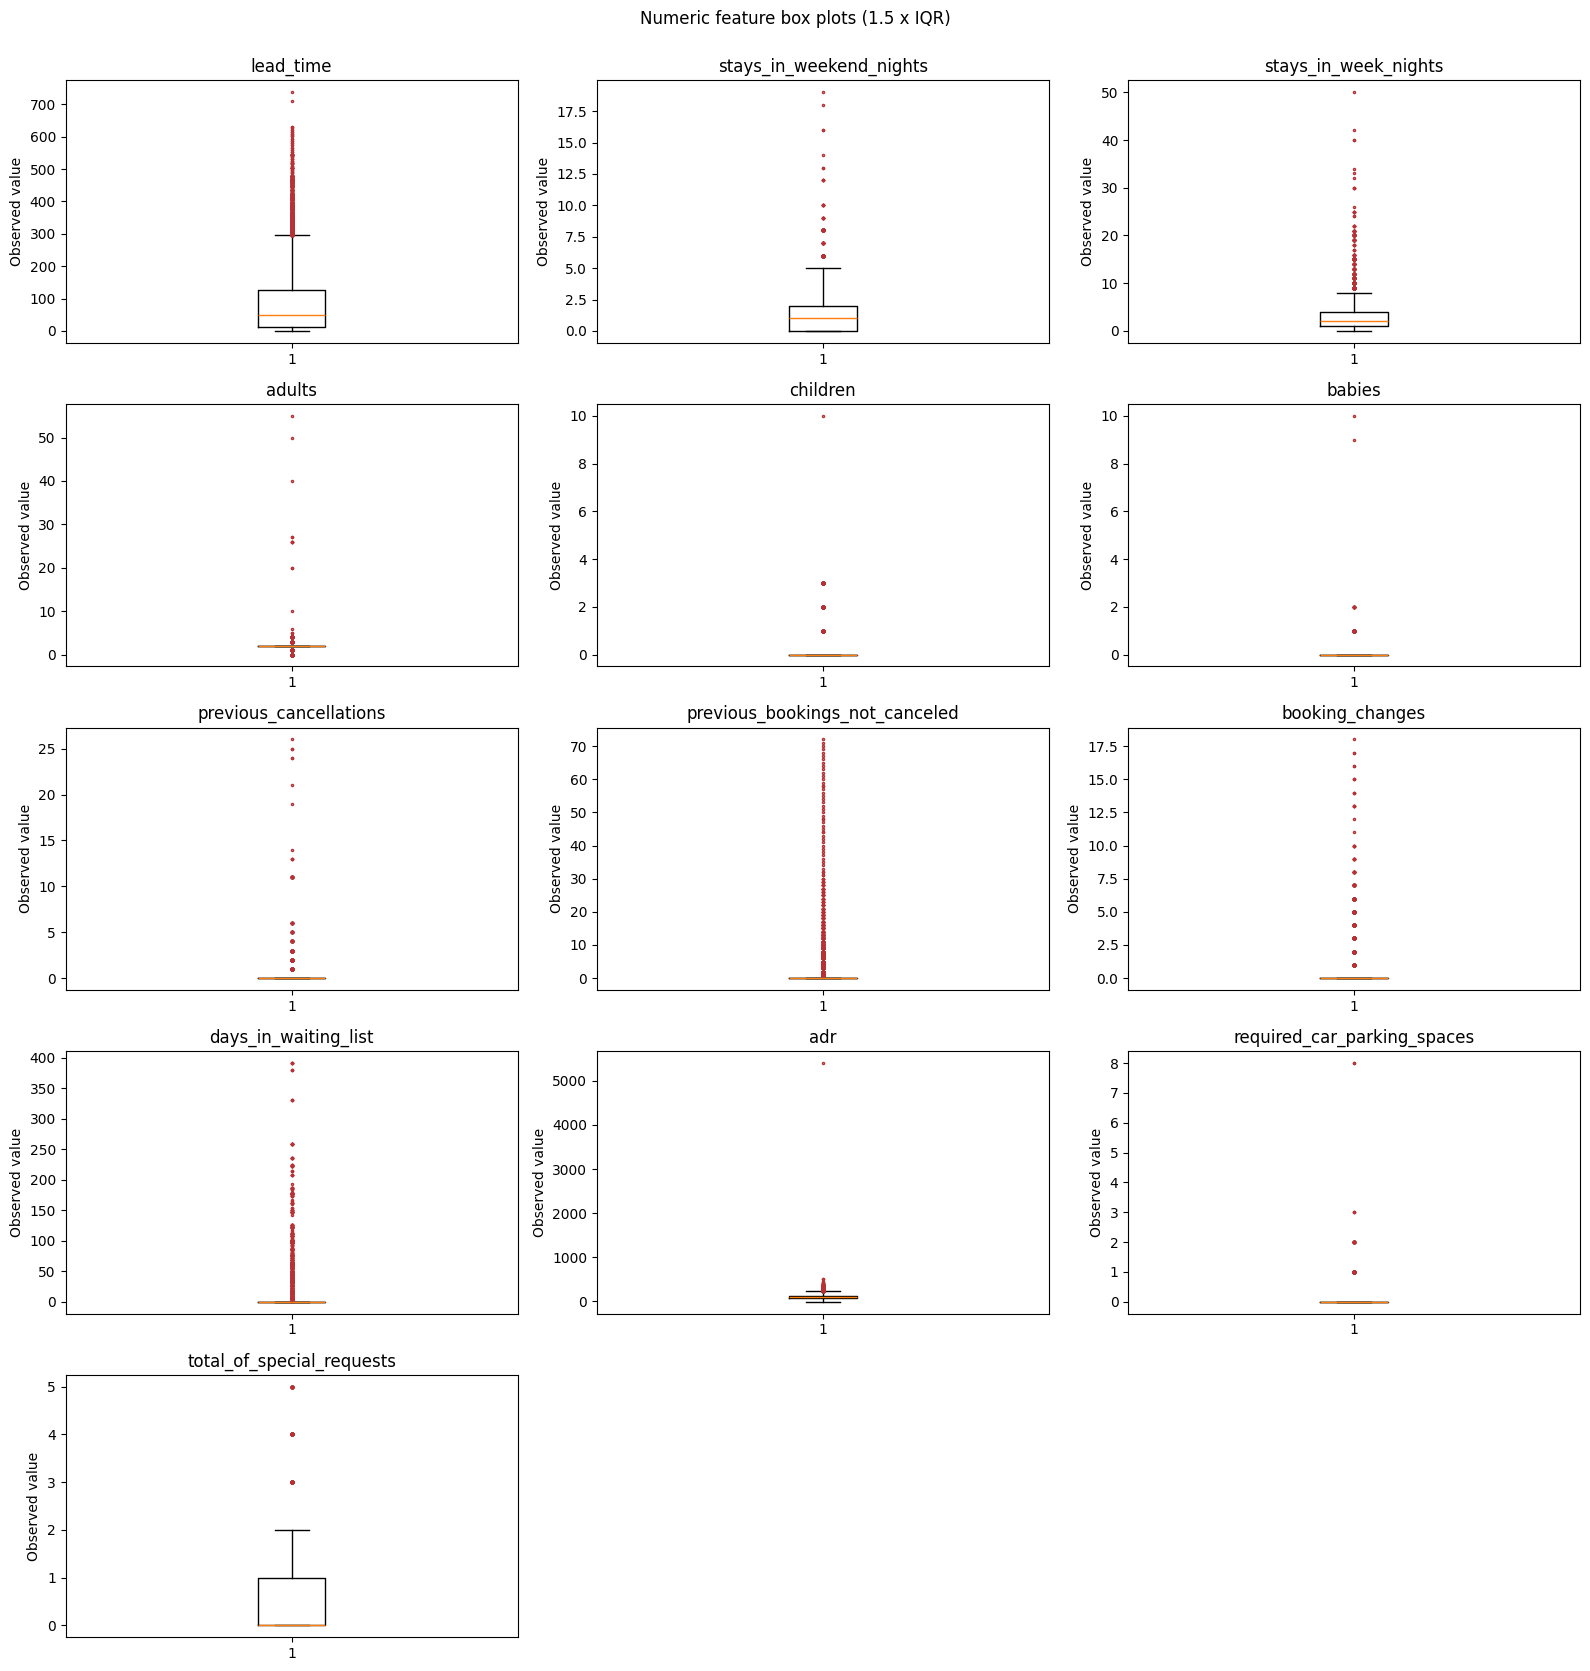

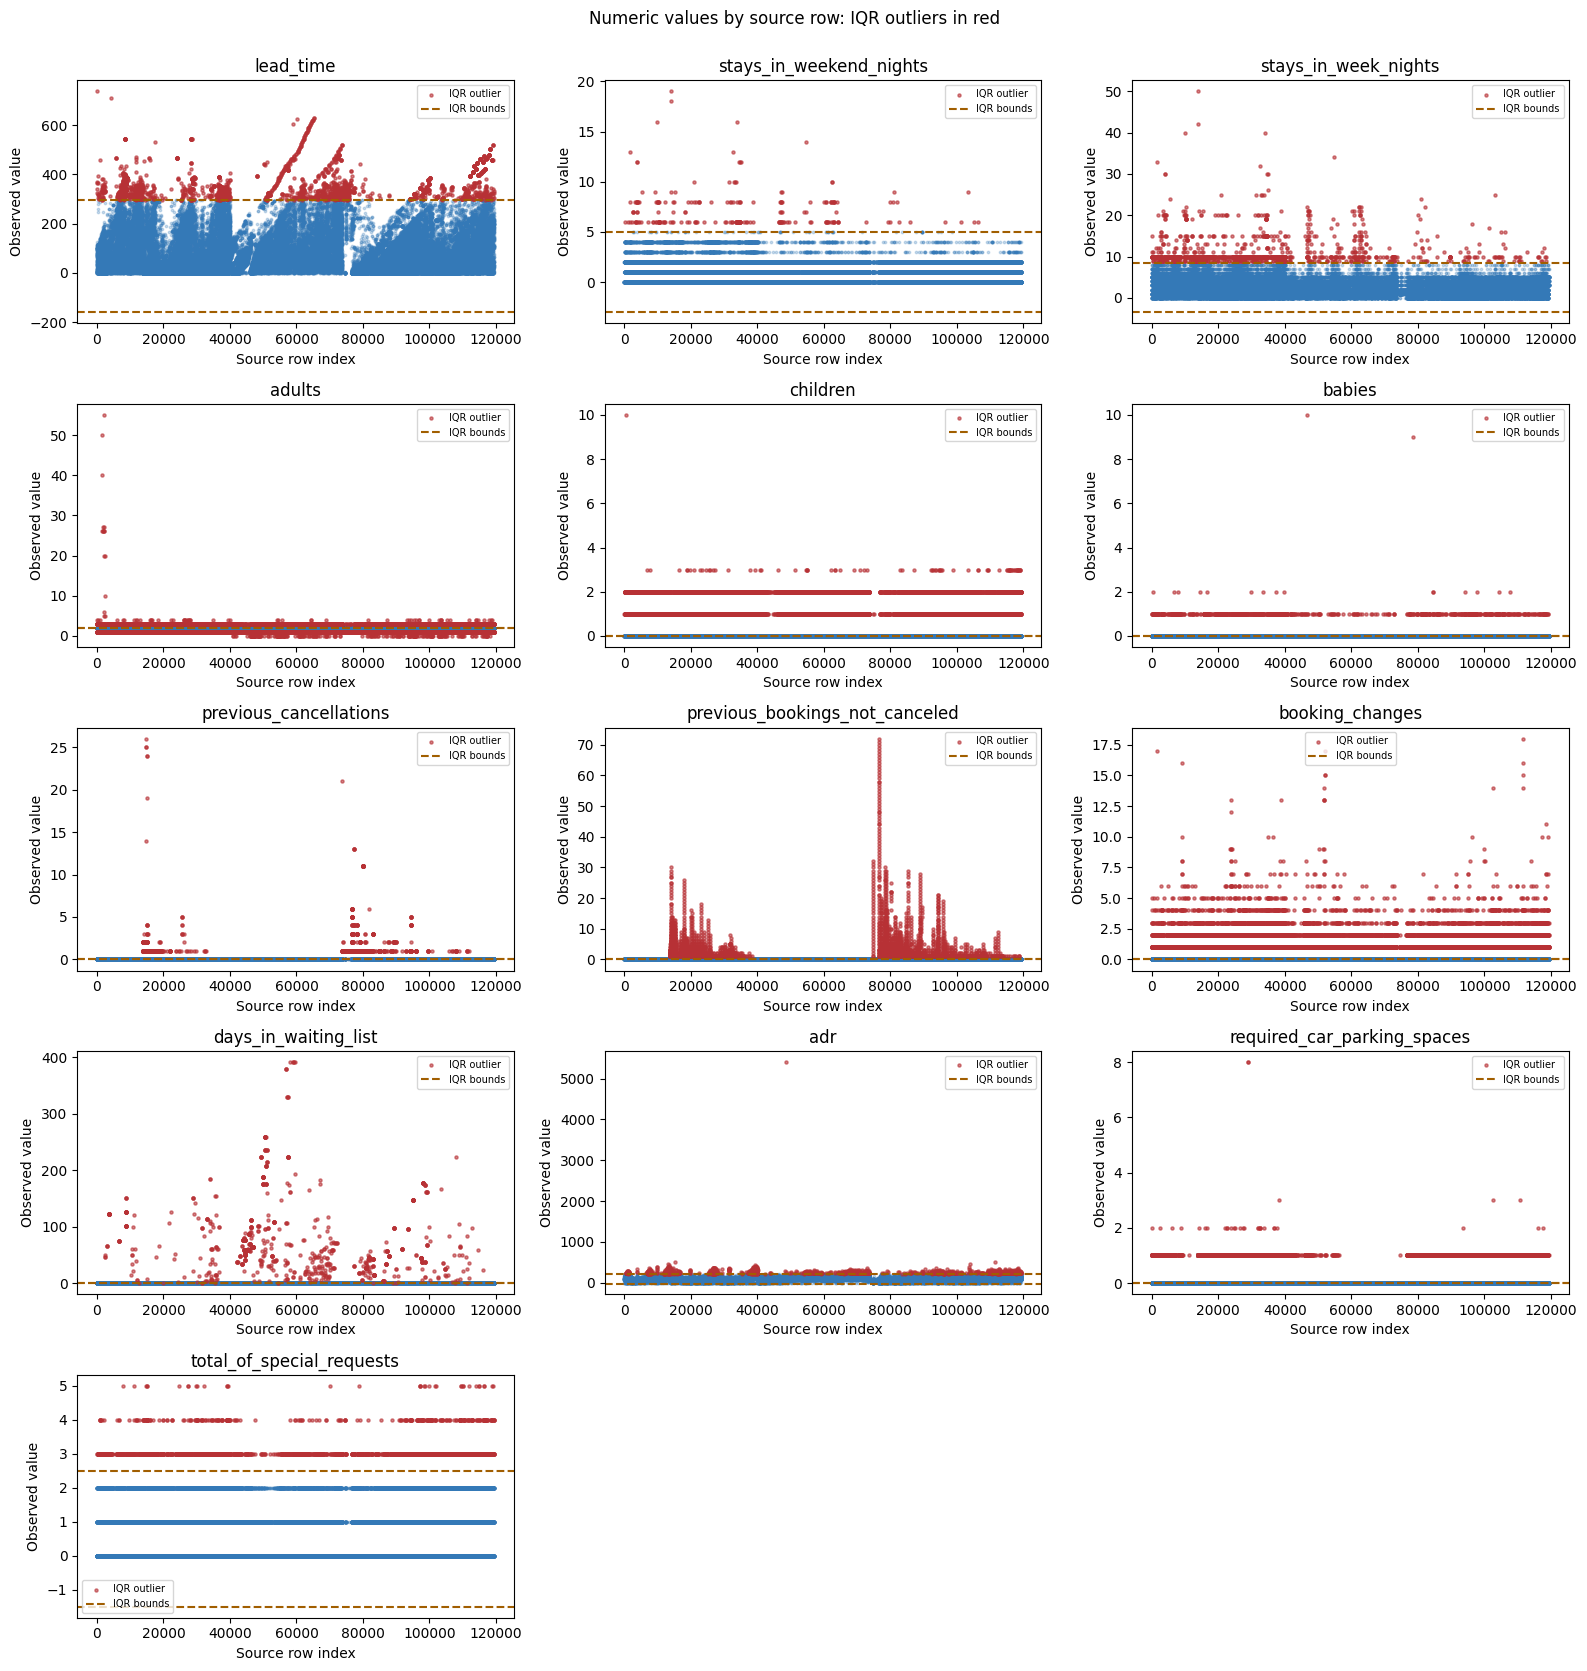

In [13]:
box_figure, scatter_figure = plot_iqr_checks(
    bookings_copy, iqr_summary, multiplier=IQR_MULTIPLIER
)
display(box_figure)
plt.close(box_figure)
display(scatter_figure)
plt.close(scatter_figure)

## 13. Seasonal Price for a Selected Room Type

Change `SELECTED_ROOM_TYPE` to select another reserved room type (default: A).
Compare mean ADR by calendar season, pooling all years, with one line per hotel.
Winter = Dec-Feb, Spring = Mar-May, Summer = Jun-Aug, Autumn = Sep-Nov.
The cleaned copy includes canceled bookings and IQR outliers. Mean ADR is booking-weighted,
not room-night-weighted. Missing groups remain gaps. Inspect counts and medians alongside means.

,season,hotel,mean_adr,median_adr,booking_count,priced_booking_count
0,Winter,City Hotel,81.039255,79.81,6940,6940
1,Winter,Resort Hotel,46.297405,43.0,4151,4151
2,Spring,City Hotel,101.415898,99.0,10488,10488
3,Spring,Resort Hotel,58.743956,56.0,4588,4588
4,Summer,City Hotel,108.082539,107.1,11704,11704
5,Summer,Resort Hotel,135.753817,132.8,5486,5486
6,Autumn,City Hotel,99.175876,95.0,8557,8557
7,Autumn,Resort Hotel,58.91235,52.8,4314,4314


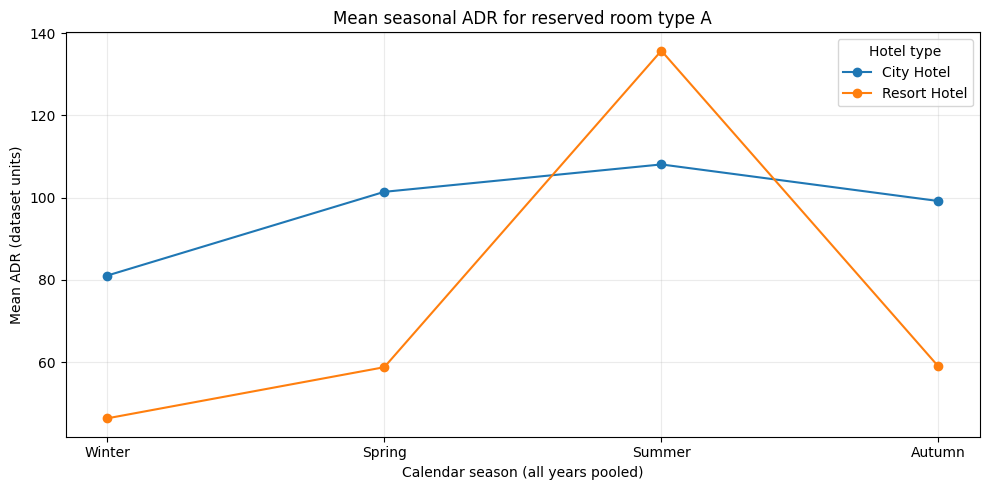

,season,hotel,mean_adr,median_adr,booking_count,priced_booking_count
0,Winter,City Hotel,78.937993,77.86,269,269
1,Winter,Resort Hotel,<NA>,<NA>,<NA>,<NA>
2,Spring,City Hotel,95.540829,93.82,205,205
3,Spring,Resort Hotel,90.0,90.0,2,2
4,Summer,City Hotel,94.080576,93.25,347,347
5,Summer,Resort Hotel,134.0,134.0,1,1
6,Autumn,City Hotel,95.645814,91.6,172,172
7,Autumn,Resort Hotel,<NA>,<NA>,<NA>,<NA>


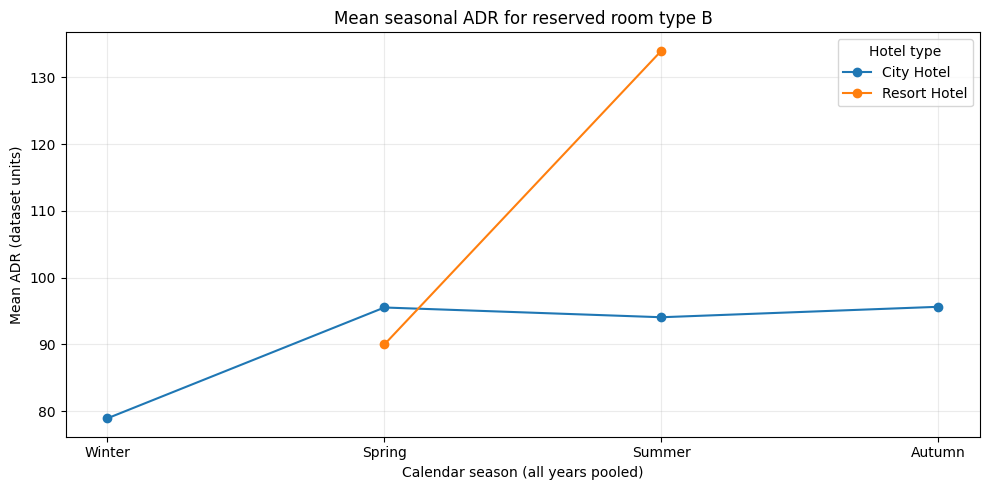

In [13]:
SELECTED_ROOM_TYPE = "A"
seasonal_prices = seasonal_room_prices(bookings_copy, SELECTED_ROOM_TYPE)
display(seasonal_prices)
seasonal_figure = plot_seasonal_prices(seasonal_prices, SELECTED_ROOM_TYPE)
display(seasonal_figure)
plt.close(seasonal_figure)

SELECTED_ROOM_TYPE = "B"
seasonal_prices = seasonal_room_prices(bookings_copy, SELECTED_ROOM_TYPE)
display(seasonal_prices)
seasonal_figure = plot_seasonal_prices(seasonal_prices, SELECTED_ROOM_TYPE)
display(seasonal_figure)
plt.close(seasonal_figure)

## 14. Average Room Price by Year and Hotel

Compare average ADR across all reserved room types for each arrival year, with one line per hotel.
Canceled bookings and IQR outliers are included. Changes can reflect room-type mix as well as
price changes. Means are booking-weighted, not room-night-weighted. ADR units are not inferred.

,arrival_date_year,hotel,mean_adr,median_adr,booking_count,priced_booking_count
0,2015,City Hotel,90.11945,86.4,6487,6487
1,2015,Resort Hotel,94.56477,83.0,6746,6746
2,2016,City Hotel,108.160503,102.68,26604,26604
3,2016,Resort Hotel,90.690905,71.0,15587,15587
4,2017,City Hotel,122.318003,117.0,20008,20008
5,2017,Resort Hotel,113.115638,92.0,11540,11540


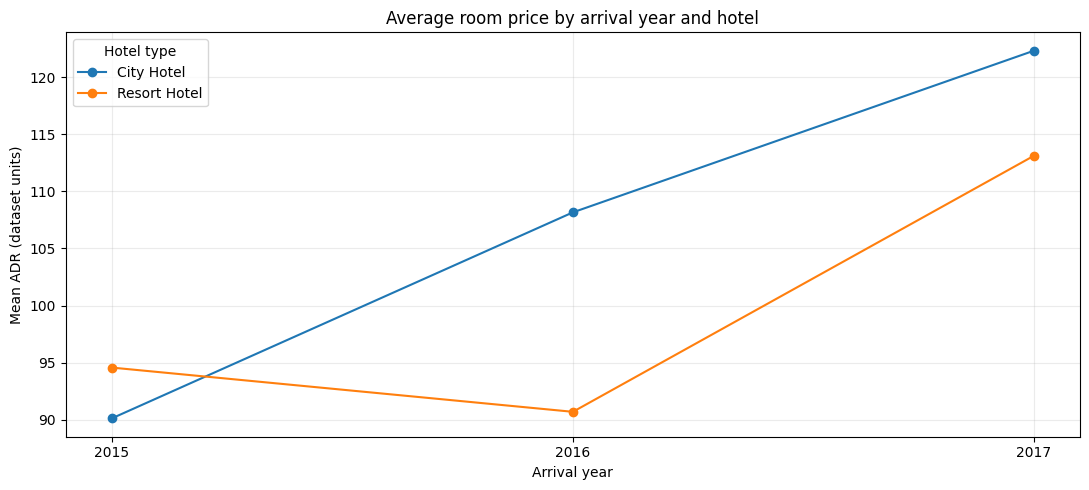

In [15]:
yearly_prices = yearly_room_prices(bookings_copy)
display(yearly_prices)
yearly_price_figure = plot_hotel_trends(
    yearly_prices, "arrival_date_year", "mean_adr",
    "Average room price by arrival year and hotel", "Mean ADR (dataset units)",
)
display(yearly_price_figure)
plt.close(yearly_price_figure)

## 15. Guest Counts by Month and Hotel

Guest count = adults + children + babies, summed over bookings, not distinct visitors or guest nights.
By default, include canceled bookings: these are booked guests, not confirmed arrivals.
Set `INCLUDE_CANCELED_GUESTS = False` to restrict both guest plots to non-canceled bookings.
If any guest count is missing, the row total is unknown and excluded from guest sums.
`complete_guest_count_bookings` reports the number of contributing bookings.

Months are ordered January-December and pooled across all available years. Partial years mean
unequal month coverage; inspect the coverage table. Each hotel has its own line.

,arrival_date_year,arrival_date_month,booking_count
0,2015,August,2442
1,2015,December,1968
2,2015,July,1663
3,2015,November,1655
4,2015,October,2689
5,2015,September,2816
6,2016,April,3750
7,2016,August,4405
8,2016,December,3128
9,2016,February,2794


,arrival_date_month,hotel,guest_count,booking_count,complete_guest_count_bookings
0,January,City Hotel,5122,2717,2717
1,January,Resort Hotel,3460,1955,1955
2,February,City Hotel,7080,3583,3583
3,February,Resort Hotel,4740,2486,2486
4,March,City Hotel,9433,4824,4824
5,March,Resort Hotel,4872,2649,2649
6,April,City Hotel,10562,5054,5054
7,April,Resort Hotel,5447,2817,2817
8,May,City Hotel,10441,5376,5376
9,May,Resort Hotel,5845,2930,2930


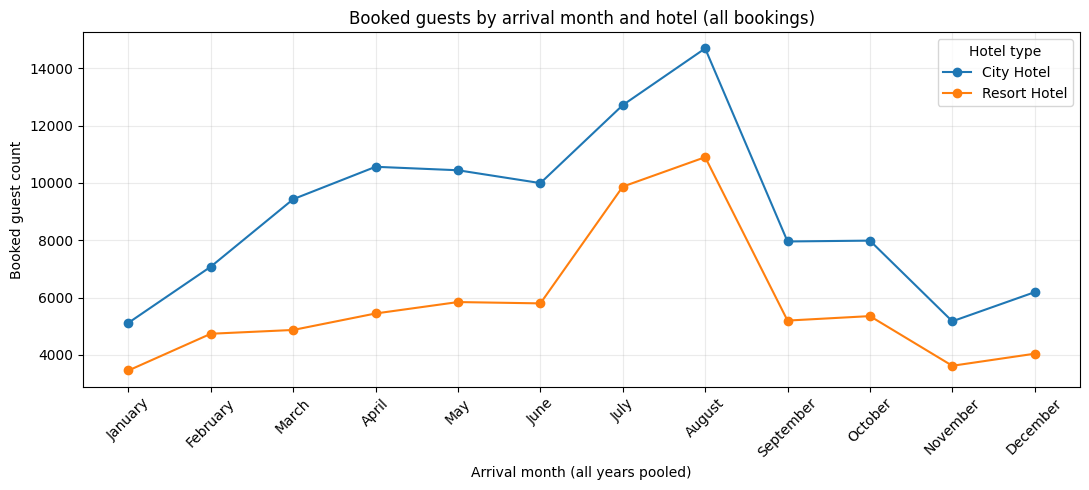

In [16]:
INCLUDE_CANCELED_GUESTS = True
coverage = bookings_copy.groupby(
    ["arrival_date_year", "arrival_date_month"]
).size().rename("booking_count").reset_index()
display(coverage)
monthly_guests = guest_counts(
    bookings_copy, "arrival_date_month", include_canceled=INCLUDE_CANCELED_GUESTS
)
display(monthly_guests)
guest_scope = "all bookings" if INCLUDE_CANCELED_GUESTS else "non-canceled bookings"
monthly_guest_figure = plot_hotel_trends(
    monthly_guests, "arrival_date_month", "guest_count",
    f"Booked guests by arrival month and hotel ({guest_scope})", "Booked guest count",
)
display(monthly_guest_figure)
plt.close(monthly_guest_figure)

## 16. Guest Counts by Year and Hotel

Use the same guest definition and cancellation setting as the monthly chart.
Each hotel has its own line. Partial years must not be compared as full calendar years.

,arrival_date_year,hotel,guest_count,booking_count,complete_guest_count_bookings
0,2015,City Hotel,11863,6487,6483
1,2015,Resort Hotel,14009,6746,6746
2,2016,City Hotel,53979,26604,26604
3,2016,Resort Hotel,31202,15587,15587
4,2017,City Hotel,41500,20008,20008
5,2017,Resort Hotel,23940,11540,11540


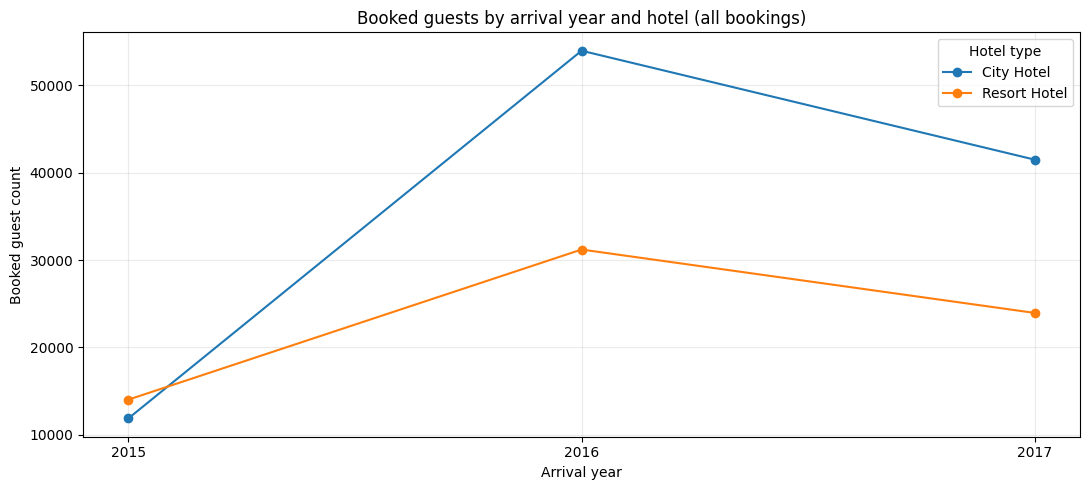

In [17]:
yearly_guests = guest_counts(
    bookings_copy, "arrival_date_year", include_canceled=INCLUDE_CANCELED_GUESTS
)
display(yearly_guests)
yearly_guest_figure = plot_hotel_trends(
    yearly_guests, "arrival_date_year", "guest_count",
    f"Booked guests by arrival year and hotel ({guest_scope})", "Booked guest count",
)
display(yearly_guest_figure)
plt.close(yearly_guest_figure)

## 16.1. Correlation Matrix
<a id="correlation-matrix"></a>

Calculate Pearson correlations between numeric columns in the cleaned `bookings_copy`.
String categories and identifier codes are excluded. Missing values are excluded separately
for each pair; undefined correlations remain blank. Numeric calendar codes require careful
interpretation. Correlation describes association, not causation.
Run the following cell after creating and cleaning `bookings_copy`. The plot is not exported.

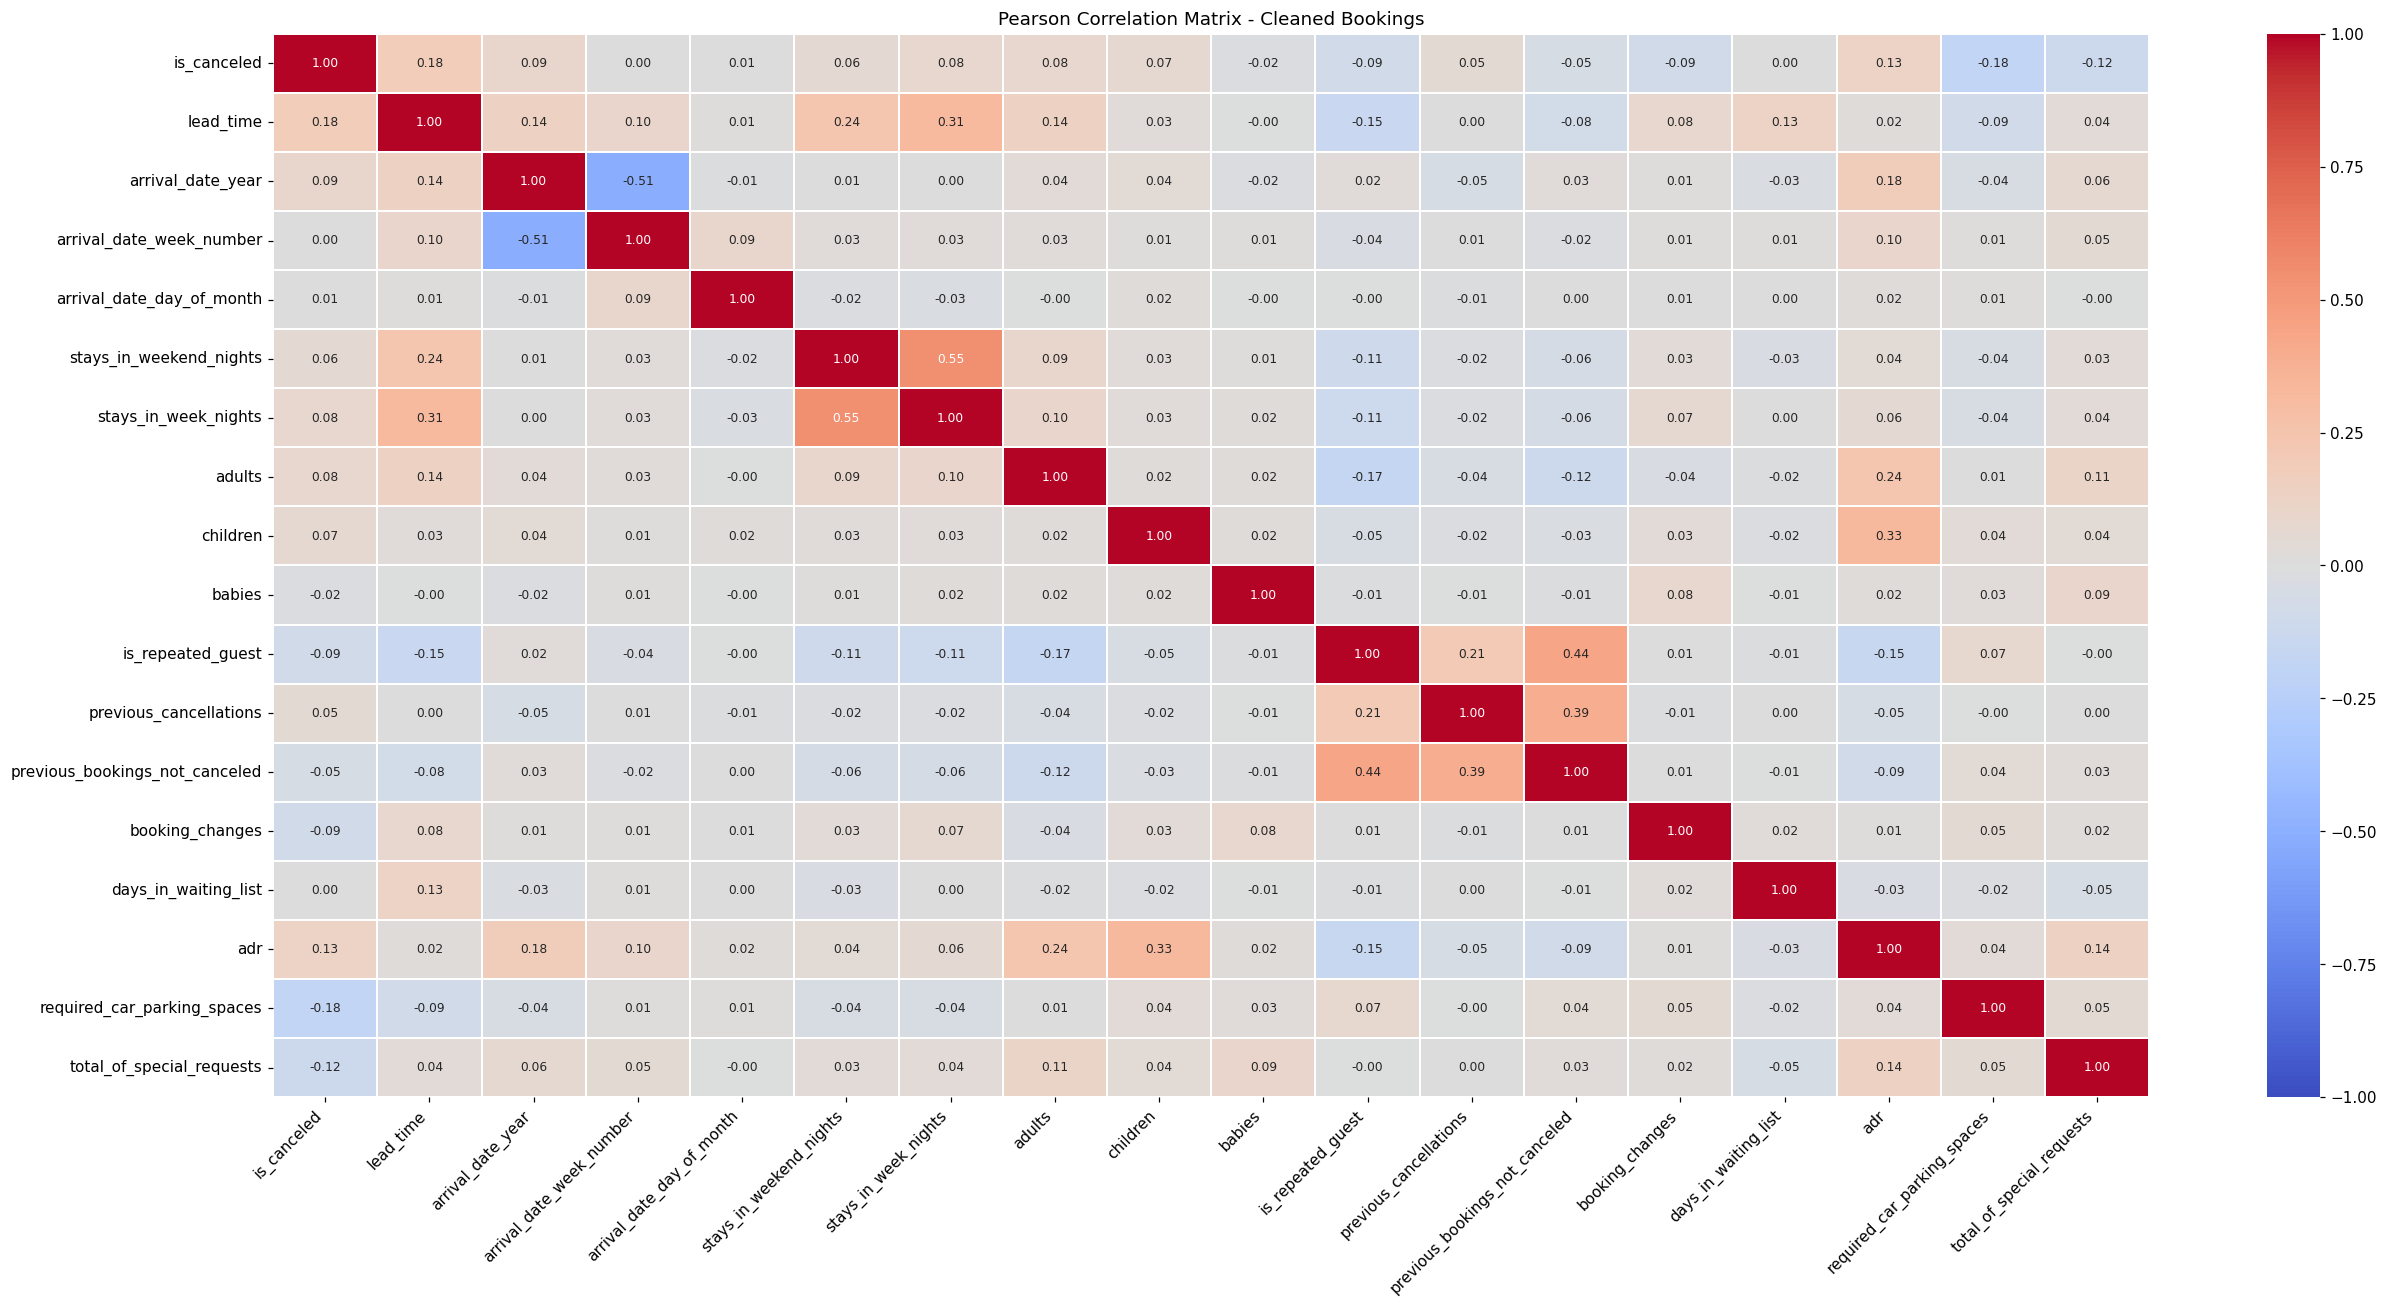

In [19]:
import seaborn as sns

corr = bookings_copy.select_dtypes(include="number").corr(method="pearson", min_periods=2)

correlation_figure, correlation_axis = plt.subplots(figsize=(24, 12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    linewidths=1,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8},
    ax=correlation_axis,
)
correlation_axis.set_title("Pearson Correlation Matrix - Cleaned Bookings")
plt.setp(correlation_axis.get_xticklabels(), rotation=45, ha="right")
plt.setp(correlation_axis.get_yticklabels(), rotation=0)
correlation_figure.tight_layout()
display(correlation_figure)
plt.close(correlation_figure)

## 17. Chi-Square Test for Categorical Features

Test each listed categorical feature against the binary target `is_canceled` using the cleaned
`bookings_copy`. Include explicitly selected numeric category codes (`arrival_date_year` and
`is_repeated_guest`), but exclude continuous measurements, the target itself, identifier codes
(`agent`, `company`), and the removed leakage columns.

- **H0:** The feature and cancellation status are independent.
- **H1:** They are associated.
- Use Pearson's chi-square test on category-by-target count tables, with no Yates correction.
- Exclude missing feature/target pairs separately for each feature; report excluded row counts.
- Use alpha = 0.05 and Bonferroni-adjusted p-values because multiple features are tested.
- Report expected counts. Flag tables if any expected count is below 1 or more than 20% are below 5.
  Flagged p-values require further review; categories are not automatically merged.
- A significant result indicates association, not its strength, direction, causality, or predictive
  usefulness. A nonsignificant result does not prove independence. Repeated guests can also violate
  the independent-observation assumption; removing exact duplicates alone does not resolve this.

Full count tables remain in memory in `contingency_tables`, for example
`display(contingency_tables["hotel"])`. No files are exported.

Extremely small p-values may display as zero because of floating-point underflow; this does not mean the probability is exactly zero.

In [20]:
import numpy as np
from scipy.stats import chi2_contingency

TARGET_COLUMN = "is_canceled"
CHI_SQUARE_ALPHA = 0.05
CATEGORICAL_FEATURES = (
    "hotel", "arrival_date_year", "arrival_date_month", "meal", "country",
    "market_segment", "distribution_channel", "is_repeated_guest",
    "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type",
)


def chi_square_associations(frame, features, target, alpha=0.05):
    """Return per-feature independence checks and their observed count tables."""
    if target in features or len(features) != len(set(features)):
        raise ValueError("Features must be unique and must not include the target.")
    if not 0 < alpha < 1:
        raise ValueError("Alpha must be between zero and one.")
    missing_columns = sorted(set(features).union({target}) - set(frame.columns))
    if missing_columns:
        raise ValueError(f"Required columns not found: {missing_columns}")
    if set(frame[target].dropna().unique()) != {0, 1}:
        raise ValueError("The target must contain both binary classes: 0 and 1.")

    rows, tables = [], {}
    for feature in features:
        pairs = frame.loc[:, [feature, target]].dropna()
        observed = pd.crosstab(pairs[feature], pairs[target])
        tables[feature] = observed
        row = {
            "feature": feature, "rows_used": len(pairs),
            "rows_excluded": len(frame) - len(pairs),
            "categories": observed.shape[0],
        }
        if observed.shape[0] < 2 or observed.shape[1] < 2:
            row.update(chi2=np.nan, degrees_of_freedom=np.nan, p_value=np.nan,
                       min_expected=np.nan, expected_below_5_percent=np.nan,
                       assumption_warning=True, status="not_testable")
        else:
            statistic, p_value, degrees, expected = chi2_contingency(observed, correction=False)
            below_5_percent = 100 * (expected < 5).mean()
            row.update(
                chi2=statistic, degrees_of_freedom=degrees, p_value=p_value,
                min_expected=expected.min(), expected_below_5_percent=below_5_percent,
                assumption_warning=bool((expected < 1).any() or below_5_percent > 20),
                status="tested",
            )
        rows.append(row)
    summary = pd.DataFrame(rows)
    tested_count = int(summary["p_value"].notna().sum())
    summary["p_value_bonferroni"] = (summary["p_value"] * tested_count).clip(upper=1)
    summary["reject_h0_adjusted"] = summary["p_value_bonferroni"].lt(alpha).astype("boolean")
    summary.loc[summary["p_value"].isna(), "reject_h0_adjusted"] = pd.NA
    return summary.sort_values("p_value_bonferroni", na_position="last").reset_index(drop=True), tables

In [21]:
chi_square_summary, contingency_tables = chi_square_associations(
    bookings_copy, CATEGORICAL_FEATURES, TARGET_COLUMN, alpha=CHI_SQUARE_ALPHA
)

print(f"Target: {TARGET_COLUMN}; alpha: {CHI_SQUARE_ALPHA}; correction: Bonferroni")
display(chi_square_summary.style.format({
    "chi2": "{:.3f}",
    "p_value": "{:.3e}",
    "p_value_bonferroni": "{:.3e}",
    "min_expected": "{:.3f}",
    "expected_below_5_percent": "{:.2f}",
}, na_rep="Not available"))

flagged_features = chi_square_summary.loc[
    chi_square_summary["assumption_warning"], "feature"
].tolist()
print("Features requiring expected-frequency review:", flagged_features)
print("Significance alone does not measure association strength or feature importance.")

Target: is_canceled; alpha: 0.05; correction: Bonferroni
Features requiring expected-frequency review: ['market_segment', 'country', 'assigned_room_type']
Significance alone does not measure association strength or feature importance.


,feature,rows_used,rows_excluded,categories,chi2,degrees_of_freedom,p_value,min_expected,expected_below_5_percent,assumption_warning,status,p_value_bonferroni,reject_h0_adjusted
0,market_segment,86972,0,8,4300.095,7,0.000e+00,0.546,12.50,True,tested,0.000e+00,True
1,distribution_channel,86972,0,5,2013.930,4,0.000e+00,1.365,20.00,False,tested,0.000e+00,True
2,country,86526,446,177,3251.347,176,0.000e+00,0.274,49.15,True,tested,0.000e+00,True
3,customer_type,86972,0,4,1522.567,3,0.000e+00,147.741,0.00,False,tested,0.000e+00,True
4,deposit_type,86972,0,3,2346.964,2,0.000e+00,29.220,0.00,False,tested,0.000e+00,True
5,arrival_date_year,86972,0,3,691.138,2,8.343e-151,3613.772,0.00,False,tested,1.001e-149,True
6,is_repeated_guest,86972,0,2,677.495,1,2.343e-149,918.395,0.00,False,tested,2.811e-148,True
7,assigned_room_type,86972,0,11,707.235,10,1.757e-145,0.273,9.09,True,tested,2.108e-144,True
8,arrival_date_month,86972,0,12,649.085,11,4.374e-132,1275.867,0.00,False,tested,5.249e-131,True
9,hotel,86972,0,2,450.080,1,6.930e-100,9250.306,0.00,False,tested,8.316e-99,True


## 18. Integrity Checks

Confirm raw records remain unchanged, leakage fields are absent, duplicate removal is complete,
and all-zero guest rows are absent. The optional CSV export below is the only file-export cell.
Any future learned transformations must be fit only on training data.

In [18]:
assert pd.util.hash_pandas_object(raw_bookings, index=True).equals(raw_fingerprint)
assert set(LEAKAGE_COLUMNS).issubset(raw_bookings.columns)
assert not set(LEAKAGE_COLUMNS).intersection(bookings_copy.columns)
assert not bookings_copy.duplicated().any()
assert not zero_guest_mask(bookings_copy).any()
assert len(bookings_copy) == len(raw_bookings) - duplicate_rows_removed - zero_guest_rows_removed
print("Raw data unchanged; cleaned copy passed all integrity checks.")
print(f"Final bookings_copy shape: {bookings_copy.shape}")

Raw data unchanged; cleaned copy passed all integrity checks.
Final bookings_copy shape: (86972, 30)


## 19. Export `bookings_copy` to CSV (Optional)

Run the following cell to save `bookings_copy` as `data/bookings_preprocessed_copy.csv`.
The source CSV is preserved. Exclude the dataframe index and write missing values as empty cells.
Running this cell again replaces the previous exported copy. This cell is left unexecuted.

In [ ]:
BOOKINGS_COPY_PATH = PROJECT_ROOT / "data" / "bookings_preprocessed_copy.csv"
bookings_copy.to_csv(BOOKINGS_COPY_PATH, index=False, encoding="utf-8-sig")
print(f"Saved {len(bookings_copy):,} rows to {BOOKINGS_COPY_PATH}")